<a href="https://colab.research.google.com/github/himank8907/TrustFlow-Fraud-Detection-with-Trust-Scores/blob/main/Copy_of_ML_project_1st_phase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       TRUSTFLOW ML ENGINE

Please upload your existing CSV dataset.


Saving trustflow_synthetic_dataset.csv to trustflow_synthetic_dataset.csv

DATASET SUCCESSFULLY LOADED!
File: trustflow_synthetic_dataset.csv
Total records: 12000


,user_trust_score,merchant_trust_score,transaction_reliability_score,behavioural_safety_score,fraud_label
0,40,68,95,68,0
1,86,65,69,44,0
2,78,39,75,58,0
3,63,42,58,87,0
4,63,74,93,75,0



DATA VALIDATION PASSED!

Class Distribution:
fraud_label
0    10397
1     1603
Name: count, dtype: int64

Synthetic Fraud Share: 13.36 %


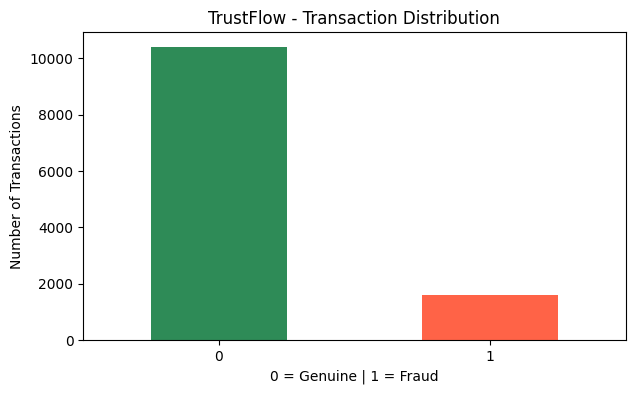

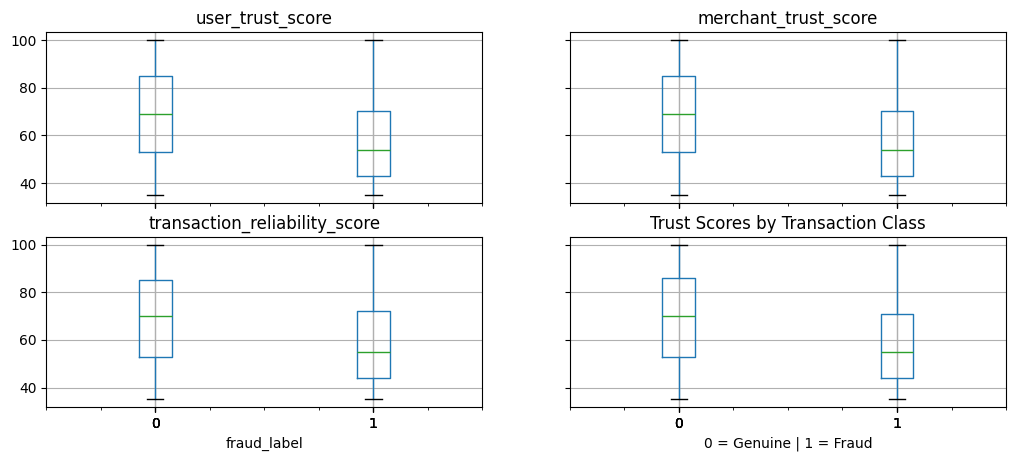


DATA SPLIT
--------------------------
Training records: 8400
Validation records: 1800
Testing records: 1800

Training: Logistic Regression

Training: Random Forest

VALIDATION MODEL COMPARISON


,Model,Precision,Recall,F1,PR-AUC,ROC-AUC
0,Logistic Regression,0.2901,0.7510,0.4185,0.5068,0.8244
1,Random Forest,0.4007,0.5021,0.4457,0.4874,0.8023



SELECTED MODEL: Logistic Regression

THRESHOLD OPTIMIZATION
--------------------------
Original threshold: 0.50
Optimized threshold: 0.7467
Validation F1: 0.5101

          FINAL TEST RESULTS
Selected Model: Logistic Regression
Precision: 0.5
Recall: 0.375
F1 Score: 0.4286
PR-AUC: 0.4562
ROC-AUC: 0.8163

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Genuine       0.91      0.94      0.92      1560
       Fraud       0.50      0.38      0.43       240

    accuracy                           0.87      1800
   macro avg       0.70      0.66      0.68      1800
weighted avg       0.85      0.87      0.86      1800


CONFUSION MATRIX
[[True Negative, False Positive],
 [False Negative, True Positive]]
[[1470   90]
 [ 150   90]]


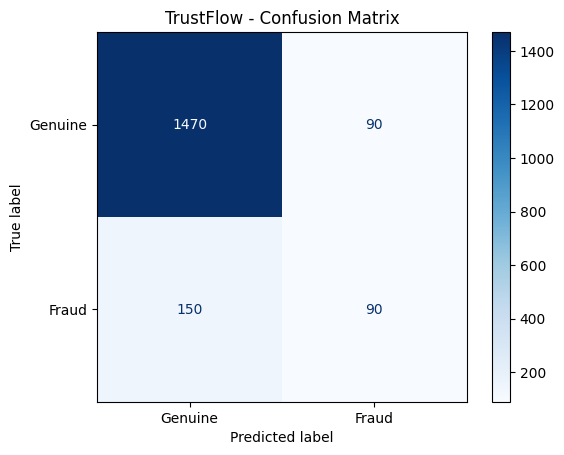

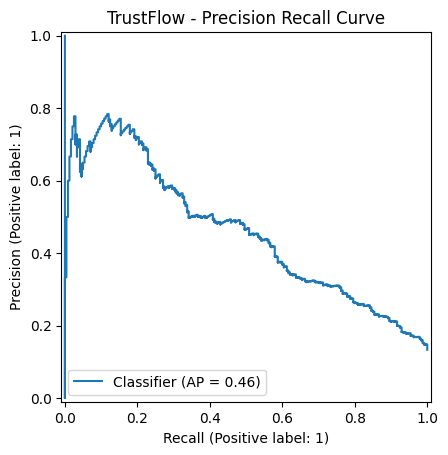

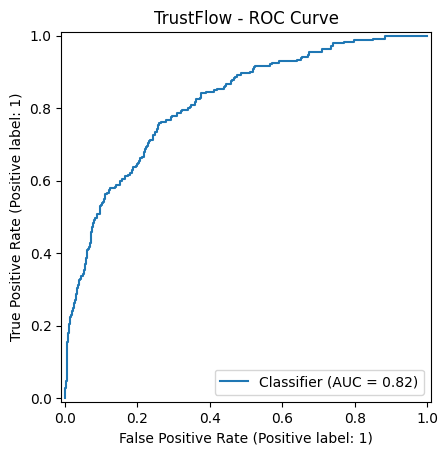


FEATURE IMPORTANCE


,Feature,Importance / Coefficient,Absolute Importance
1,merchant_trust_score,-0.7000,0.7000
3,behavioural_safety_score,-0.6623,0.6623
0,user_trust_score,-0.6574,0.6574
2,transaction_reliability_score,-0.6355,0.6355


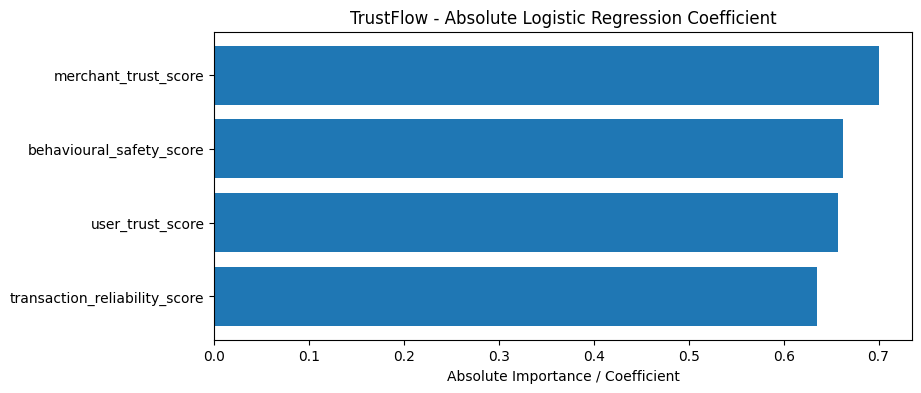


       TRUSTFLOW REPORT
Selected ML Model: Logistic Regression
ML Fraud Probability: 78.36 %
ML Prediction: FRAUD
Overall Trust Score: 55.5
TrustFlow Action: REVIEW

MODEL SAVED SUCCESSFULLY!



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


     TRUSTFLOW ML PIPELINE COMPLETED


In [1]:

# ============================================================
# TRUSTFLOW - PAYMENT RISK ENGINE
# COMPLETE UPDATED ML PIPELINE
# Existing CSV Upload + Model Training + Evaluation + Prediction
# ============================================================


# 1. INSTALL AND IMPORT LIBRARIES

!pip install -q scikit-learn joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    precision_recall_curve
)

print("==========================================")
print("       TRUSTFLOW ML ENGINE")
print("==========================================")


# ============================================================
# 2. UPLOAD EXISTING TRUSTFLOW CSV DATASET
# ============================================================

print("\nPlease upload your existing CSV dataset.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No dataset uploaded!")

# Prefer the original filename; otherwise use first uploaded CSV

expected_filename = "trustflow_synthetic_dataset.csv"

if expected_filename in uploaded:
    csv_filename = expected_filename
else:
    csv_files = [
        name for name in uploaded.keys()
        if name.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError("Please upload a CSV file.")

    csv_filename = csv_files[0]

data = pd.read_csv(csv_filename)

print("\nDATASET SUCCESSFULLY LOADED!")
print("File:", csv_filename)
print("Total records:", len(data))

display(data.head())


# ============================================================
# 3. DATA VALIDATION
# ============================================================

features = [
    "user_trust_score",
    "merchant_trust_score",
    "transaction_reliability_score",
    "behavioural_safety_score"
]

target = "fraud_label"

required_columns = features + [target]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Check missing values

if data[required_columns].isnull().any().any():
    raise ValueError(
        "Dataset contains missing values. Please clean the CSV."
    )

# Check numeric data

for col in required_columns:
    data[col] = pd.to_numeric(data[col], errors="raise")

# Validate feature ranges

for col in features:
    if not data[col].between(35, 100).all():
        raise ValueError(
            f"{col} contains values outside 35-100."
        )

# Validate target labels

if not set(data[target].unique()).issubset({0, 1}):
    raise ValueError(
        "fraud_label must contain only 0 and 1."
    )

if data[target].nunique() != 2:
    raise ValueError(
        "Dataset must contain both genuine and fraud classes."
    )

print("\nDATA VALIDATION PASSED!")

print("\nClass Distribution:")
print(data[target].value_counts().sort_index())

print(
    "\nSynthetic Fraud Share:",
    round(data[target].mean() * 100, 2),
    "%"
)


# ============================================================
# 4. DATA VISUALIZATION
# ============================================================

plt.figure(figsize=(7, 4))

data[target].value_counts().sort_index().plot(
    kind="bar",
    color=["seagreen", "tomato"]
)

plt.title("TrustFlow - Transaction Distribution")
plt.xlabel("0 = Genuine | 1 = Fraud")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()


data.boxplot(
    column=features,
    by=target,
    figsize=(12, 5)
)

plt.suptitle("")
plt.title("Trust Scores by Transaction Class")
plt.xlabel("0 = Genuine | 1 = Fraud")
plt.ylabel("Trust Score")
plt.show()


# ============================================================
# 5. FEATURE SELECTION
# ============================================================

X = data[features]
y = data[target].astype(int)


# ============================================================
# 6. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# 70% training data and 30% temporary data

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Divide remaining 30% into 15% validation and 15% test

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDATA SPLIT")
print("--------------------------")
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))


# ============================================================
# 7. INITIALIZE MACHINE LEARNING MODELS
# ============================================================

models = {

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}


# ============================================================
# 8. MODEL TRAINING AND VALIDATION
# ============================================================

fitted_models = {}
validation_results = []

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    fitted_models[name] = model

    val_probabilities = model.predict_proba(X_val)[:, 1]

    val_predictions = (
        val_probabilities >= 0.50
    ).astype(int)

    validation_results.append({

        "Model": name,

        "Precision": precision_score(
            y_val,
            val_predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            val_predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_val,
            val_predictions,
            zero_division=0
        ),

        "PR-AUC": average_precision_score(
            y_val,
            val_probabilities
        ),

        "ROC-AUC": roc_auc_score(
            y_val,
            val_probabilities
        )
    })


validation_comparison = pd.DataFrame(
    validation_results
).sort_values(
    "PR-AUC",
    ascending=False
)

print("\nVALIDATION MODEL COMPARISON")

display(validation_comparison.round(4))


# ============================================================
# 9. SELECT BEST MODEL
# ============================================================

best_name = validation_comparison.iloc[0]["Model"]

best_model = fitted_models[best_name]

print("\nSELECTED MODEL:", best_name)


# ============================================================
# 10. OPTIMIZE CLASSIFICATION THRESHOLD
# ============================================================

val_probabilities = best_model.predict_proba(X_val)[:, 1]

precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_val,
        val_probabilities
    )
)

# Calculate F1 score for each available threshold

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    /
    (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-12
    )
)

best_threshold_index = int(np.argmax(f1_values))

best_threshold = float(
    thresholds[best_threshold_index]
)

print("\nTHRESHOLD OPTIMIZATION")
print("--------------------------")
print("Original threshold: 0.50")
print("Optimized threshold:", round(best_threshold, 4))
print(
    "Validation F1:",
    round(float(f1_values[best_threshold_index]), 4)
)


# ============================================================
# 11. FINAL MODEL EVALUATION
# ============================================================

# Test dataset is used only for final evaluation

test_probabilities = best_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)

pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

print("\n==========================================")
print("          FINAL TEST RESULTS")
print("==========================================")

print("Selected Model:", best_name)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("PR-AUC:", round(pr_auc, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

print("\nCONFUSION MATRIX")
print("[[True Negative, False Positive],")
print(" [False Negative, True Positive]]")

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Genuine", "Fraud"],
    cmap="Blues"
)

plt.title("TrustFlow - Confusion Matrix")
plt.show()


# ============================================================
# 13. PRECISION-RECALL CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("TrustFlow - Precision Recall Curve")
plt.show()


# ============================================================
# 14. ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("TrustFlow - ROC Curve")
plt.show()


# ============================================================
# 15. FEATURE IMPORTANCE
# ============================================================

if best_name == "Random Forest":

    importance_values = best_model.feature_importances_

    importance_label = "Random Forest Importance"

else:

    importance_values = (
        best_model.named_steps["logisticregression"].coef_[0]
    )

    importance_label = "Absolute Logistic Regression Coefficient"

importance_df = pd.DataFrame({

    "Feature": features,

    "Importance / Coefficient": importance_values

})

importance_df["Absolute Importance"] = (
    importance_df["Importance / Coefficient"].abs()
)

importance_df = importance_df.sort_values(
    "Absolute Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE")
display(importance_df.round(4))

plt.figure(figsize=(9, 4))

plt.barh(
    importance_df["Feature"],
    importance_df["Absolute Importance"]
)

plt.title("TrustFlow - " + importance_label)
plt.xlabel("Absolute Importance / Coefficient")
plt.gca().invert_yaxis()
plt.show()


# ============================================================
# 16. TRUST SCORE CALCULATION
# ============================================================

def calculate_trust_score(example):

    score = (
        0.30 * example["user_trust_score"]
        + 0.30 * example["merchant_trust_score"]
        + 0.25 * example["transaction_reliability_score"]
        + 0.15 * example["behavioural_safety_score"]
    )

    return round(float(score), 2)


# ============================================================
# 17. REUSABLE TRANSACTION PREDICTION FUNCTION
# ============================================================

def predict_transaction(
    user_score,
    merchant_score,
    reliability_score,
    behaviour_score
):

    values = [
        user_score,
        merchant_score,
        reliability_score,
        behaviour_score
    ]

    if not all(
        isinstance(value, (int, float, np.integer, np.floating))
        and np.isfinite(value)
        and 35 <= value <= 100
        for value in values
    ):

        raise ValueError(
            "All four scores must be between 35 and 100."
        )

    transaction = pd.DataFrame([{

        "user_trust_score": user_score,

        "merchant_trust_score": merchant_score,

        "transaction_reliability_score": reliability_score,

        "behavioural_safety_score": behaviour_score

    }])[features]

    fraud_probability = best_model.predict_proba(
        transaction
    )[0, 1]

    fraud_prediction = int(
        fraud_probability >= best_threshold
    )

    overall_trust_score = calculate_trust_score(
        transaction.iloc[0]
    )

    # TrustFlow decision rules

    if overall_trust_score < 40:

        trustflow_action = "BLOCK"

    elif overall_trust_score < 70:

        trustflow_action = "REVIEW"

    else:

        trustflow_action = "APPROVE"

    print("\n================================")
    print("       TRUSTFLOW REPORT")
    print("================================")

    print("Selected ML Model:", best_name)

    print(
        "ML Fraud Probability:",
        round(float(fraud_probability) * 100, 2),
        "%"
    )

    print(
        "ML Prediction:",
        "FRAUD" if fraud_prediction == 1 else "GENUINE"
    )

    print("Overall Trust Score:", overall_trust_score)

    print("TrustFlow Action:", trustflow_action)

    print("================================")

    return {

        "model": best_name,

        "fraud_probability": float(fraud_probability),

        "fraud_prediction": fraud_prediction,

        "trust_score": overall_trust_score,

        "action": trustflow_action

    }


# ============================================================
# 18. TEST EXAMPLE TRANSACTION
# ============================================================

example_result = predict_transaction(

    user_score=45,

    merchant_score=60,

    reliability_score=72,

    behaviour_score=40

)


# ============================================================
# 19. SAVE COMPLETE TRAINED MODEL
# ============================================================

model_package = {

    "model": best_model,

    "features": features,

    "threshold": best_threshold,

    "model_name": best_name,

    "trust_score_weights": {

        "user_trust_score": 0.30,

        "merchant_trust_score": 0.30,

        "transaction_reliability_score": 0.25,

        "behavioural_safety_score": 0.15
    },

    "dataset_rows": len(data),

    "data_type": "synthetic demonstration",

    "evaluation_metrics": {

        "precision": precision,

        "recall": recall,

        "f1": f1,

        "pr_auc": pr_auc,

        "roc_auc": roc_auc
    }

}

joblib.dump(
    model_package,
    "trustflow_updated_model.joblib"
)

print("\nMODEL SAVED SUCCESSFULLY!")


# ============================================================
# 20. DOWNLOAD TRAINED MODEL
# ============================================================

print("\nDownloading trained model...")

files.download("trustflow_updated_model.joblib")

print("\n==========================================")
print("     TRUSTFLOW ML PIPELINE COMPLETED")
print("==========================================")
